## Jawad Hassan 2230-0035
## Nlp Class Activity
## Sir Umer Farooq
## Task Convert Imdb Data To Vectors Then Ml Models

# Sentiment Analysis — Comparing 5 Word Embedding Methods

## Text preprocessing already applied to this IMDB dataset

1. HTML tags removed — reviews had `<br />` tags (601 of 1000 rows)
2. Lowercasing — all text converted to small letters
3. Punctuation removed — commas, full stops, quotes
4. Stopwords removed — common words like "the", "a", "is"
5. Negations kept on purpose — "not", "no", "never" were NOT removed, because they carry the sentiment

## Preprocessing I am adding myself

6. Numbers removed — some reviews wrote ratings like "2/10", which became the word "210" after punctuation was stripped. This leaks the answer, so the model would read the score instead of understanding the words.
7. Broken characters removed — 41 reviews had damaged symbols from a file encoding problem

In [1]:
import pandas as pd
import numpy as np

pd.set_option('display.max_colwidth', 100)

In [2]:
df = pd.read_csv("imdb_clean_sample.csv")

data = df[['clean', 'sentiment']].copy()
data.columns = ['sentence', 'sentiment']

data['sentence'] = data['sentence'].str.replace(r'\d+', ' ', regex=True)

data['sentence'] = data['sentence'].str.replace(r'[^a-z\s]', ' ', regex=True)

data['sentence'] = data['sentence'].str.replace(r'\s+', ' ', regex=True).str.strip()

data.to_csv("imdb_2col.csv", index=False)

print(data.shape)
data.head()

(1000, 2)


,sentence,sentiment
0,soul plane horrible attempt comedy appeal people thick skulls bloodshot eyes furry pawns plot no...,negative
1,guest future tells fascinating story time travel friendship battle good evil small budget child ...,positive
2,national treasure thoroughly misguided hodgepodge plot entanglements borrow nearly every cloak d...,negative
3,ok first said wanted check whether movie average rating exactly sicker killers proceedings made ...,negative
4,havent always fan show grew wasnt season started see richness show finally brought daniel jackso...,positive


In [3]:
print("digits left:", data['sentence'].str.contains(r'\d').sum())
print("empty rows:", (data['sentence'].str.len() == 0).sum())
print(data['sentiment'].value_counts())

digits left: 0
empty rows: 0
sentiment
positive    518
negative    482
Name: count, dtype: int64


In [4]:
from sklearn.model_selection import train_test_split

data = pd.read_csv("imdb_2col.csv")

X = data['sentence']
y = data['sentiment']

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("teaching pile:", X_train.shape[0], "reviews")
print("hidden pile  :", X_test.shape[0], "reviews")
print()
print(y_train.value_counts())

teaching pile: 800 reviews
hidden pile  : 200 reviews

sentiment
positive    414
negative    386
Name: count, dtype: int64


In [5]:
# Embedding #1: One-Hot Encode
# "bad bad bad" becomes 1 — it only records that the word appeared, never how many times

from sklearn.feature_extraction.text import CountVectorizer

onehot_vec = CountVectorizer(binary=True)

X_train_onehot = onehot_vec.fit_transform(X_train)
X_test_onehot  = onehot_vec.transform(X_test)

print("train shape :", X_train_onehot.shape)
print("test shape  :", X_test_onehot.shape)
print("values used :", sorted(set(X_train_onehot.data))[:5])

train shape : (800, 17530)
test shape  : (200, 17530)
values used : [np.int64(1)]


In [6]:
# Embedding #2: Bag of Words
# "bad bad bad" becomes 3 — it counts, so the model knows how strongly a word is used

bow_vec = CountVectorizer()

X_train_bow = bow_vec.fit_transform(X_train)
X_test_bow  = bow_vec.transform(X_test)

print("train shape :", X_train_bow.shape)
print("test shape  :", X_test_bow.shape)
print("max count   :", X_train_bow.max())

train shape : (800, 17530)
test shape  : (200, 17530)
max count   : 34


In [7]:
# Embedding #3: N-gram
# "not good" is kept as ONE feature — cells 5 and 6 saw only "not" and "good" separately

ngram_vec = CountVectorizer(ngram_range=(1, 2))

X_train_ngram = ngram_vec.fit_transform(X_train)
X_test_ngram  = ngram_vec.transform(X_test)

print("train shape :", X_train_ngram.shape)
print("test shape  :", X_test_ngram.shape)
print("'not good' is a column?", "not good" in ngram_vec.vocabulary_)

train shape : (800, 103537)
test shape  : (200, 103537)
'not good' is a column? True


In [8]:
# Embedding #4: TF-IDF
# "movie" appears in every review so its weight drops — rare words get boosted instead

from sklearn.feature_extraction.text import TfidfVectorizer

tfidf_vec = TfidfVectorizer()

X_train_tfidf = tfidf_vec.fit_transform(X_train)
X_test_tfidf  = tfidf_vec.transform(X_test)

print("train shape :", X_train_tfidf.shape)
print("test shape  :", X_test_tfidf.shape)
print("min value   :", round(float(X_train_tfidf.data.min()), 4))
print("max value   :", round(float(X_train_tfidf.data.max()), 4))

train shape : (800, 17530)
test shape  : (200, 17530)
min value   : 0.0062
max value   : 0.7847


In [9]:
# Embedding #5: Word2Vec trained on our own 800 reviews (skip-gram)
# Each review becomes just 100 numbers — skip-gram learns more from small data than CBOW

from gensim.models import Word2Vec

train_tokens = [s.split() for s in X_train]

w2v_model = Word2Vec(
    sentences=train_tokens,
    vector_size=100,
    window=5,
    min_count=2,
    workers=1,
    seed=42,
    sg=1
)

def review_to_vector(sentence, model, size):
    words = [w for w in sentence.split() if w in model.wv]
    if len(words) == 0:
        return np.zeros(size)
    return np.mean([model.wv[w] for w in words], axis=0)

X_train_w2v = np.array([review_to_vector(s, w2v_model, 100) for s in X_train])
X_test_w2v  = np.array([review_to_vector(s, w2v_model, 100) for s in X_test])

print("training mode      :", "skip-gram" if w2v_model.sg else "CBOW")
print("vocabulary learned :", len(w2v_model.wv))
print("train shape        :", X_train_w2v.shape)
print("test shape         :", X_test_w2v.shape)
print("has negatives      :", (X_train_w2v < 0).any())
print("min / max          :", round(float(X_train_w2v.min()),3), "/", round(float(X_train_w2v.max()),3))


training mode      : skip-gram
vocabulary learned : 8258
train shape        : (800, 100)
test shape         : (200, 100)
has negatives      : True
min / max          : -0.515 / 0.41


In [10]:
# Embedding #6: Word2Vec pretrained on Google News (100 billion words)
# Same method as cell 9, but learned from 100 billion words instead of our 800 reviews

import gensim.downloader as api

gnews = api.load('word2vec-google-news-300')

def review_to_vector_pretrained(sentence, vectors, size):
    words = [w for w in sentence.split() if w in vectors]
    if len(words) == 0:
        return np.zeros(size)
    return np.mean([vectors[w] for w in words], axis=0)

X_train_gnews = np.array([review_to_vector_pretrained(s, gnews, 300) for s in X_train])
X_test_gnews  = np.array([review_to_vector_pretrained(s, gnews, 300) for s in X_test])

print("vocabulary available :", f"{len(gnews):,}")
print("train shape          :", X_train_gnews.shape)
print("test shape           :", X_test_gnews.shape)
print("has negatives        :", (X_train_gnews < 0).any())
print("min / max            :", round(float(X_train_gnews.min()),3), "/", round(float(X_train_gnews.max()),3))

vocabulary available : 3,000,000
train shape          : (800, 300)
test shape           : (200, 300)
has negatives        : True
min / max            : -0.241 / 0.253


In [11]:
# Train and score: 6 embeddings x 2 models = 12 results
# MultinomialNB for count data, GaussianNB for Word2Vec (it has negative numbers)

from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import MultinomialNB, GaussianNB
from sklearn.metrics import accuracy_score

embeddings = {
    "One-Hot":        (X_train_onehot, X_test_onehot, "count"),
    "Bag of Words":   (X_train_bow,    X_test_bow,    "count"),
    "N-gram":         (X_train_ngram,  X_test_ngram,  "count"),
    "TF-IDF":         (X_train_tfidf,  X_test_tfidf,  "count"),
    "Word2Vec ours":  (X_train_w2v,    X_test_w2v,    "dense"),
    "Word2Vec GNews": (X_train_gnews,  X_test_gnews,  "dense"),
}

baseline = y_test.value_counts(normalize=True).max()
print(f"baseline (always guess the bigger class): {baseline:.3f}\n")

results = []

for name, (train_vec, test_vec, kind) in embeddings.items():

    rf = RandomForestClassifier(n_estimators=100, random_state=42)
    rf.fit(train_vec, y_train)
    rf_acc = accuracy_score(y_test, rf.predict(test_vec))

    nb = MultinomialNB() if kind == "count" else GaussianNB()
    nb.fit(train_vec, y_train)
    nb_acc = accuracy_score(y_test, nb.predict(test_vec))

    results.append({"Embedding": name, "Features": train_vec.shape[1],
                    "Random Forest": rf_acc, "Naive Bayes": nb_acc})

    print(f"{name:16s} features={train_vec.shape[1]:6d}  RF={rf_acc:.3f}  NB={nb_acc:.3f}")

results_df = pd.DataFrame(results)

baseline (always guess the bigger class): 0.520

One-Hot          features= 17530  RF=0.820  NB=0.840
Bag of Words     features= 17530  RF=0.800  NB=0.830
N-gram           features=103537  RF=0.810  NB=0.850
TF-IDF           features= 17530  RF=0.800  NB=0.820
Word2Vec ours    features=   100  RF=0.695  NB=0.620
Word2Vec GNews   features=   300  RF=0.785  NB=0.760


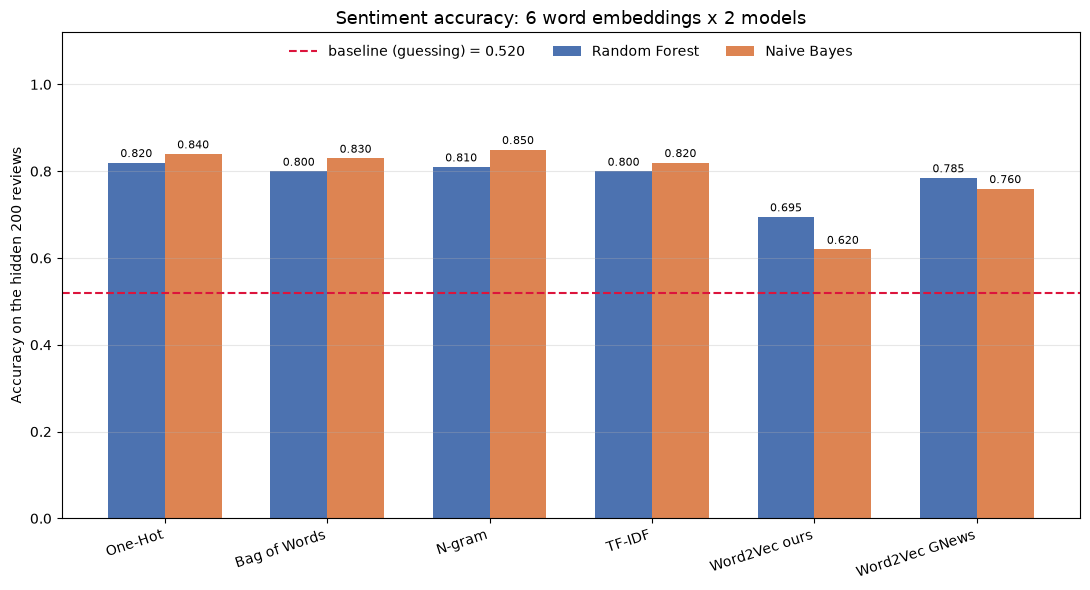

In [12]:
# Final comparison: all 12 results in one chart
# The red line is the baseline — any bar below it means the model learned nothing

import matplotlib.pyplot as plt

x = np.arange(len(results_df))
width = 0.35

fig, ax = plt.subplots(figsize=(11, 6))

b1 = ax.bar(x - width/2, results_df["Random Forest"], width,
            label="Random Forest", color="#4C72B0")
b2 = ax.bar(x + width/2, results_df["Naive Bayes"], width,
            label="Naive Bayes", color="#DD8452")

ax.axhline(baseline, color="crimson", linestyle="--", linewidth=1.5,
           label=f"baseline (guessing) = {baseline:.3f}")

ax.set_ylabel("Accuracy on the hidden 200 reviews")
ax.set_title("Sentiment accuracy: 6 word embeddings x 2 models", fontsize=13)
ax.set_xticks(x)
ax.set_xticklabels(results_df["Embedding"], rotation=18, ha="right")
ax.set_ylim(0, 1.12)
ax.bar_label(b1, fmt="%.3f", fontsize=8, padding=2)
ax.bar_label(b2, fmt="%.3f", fontsize=8, padding=2)
ax.grid(axis="y", alpha=0.3)
ax.legend(loc="upper center", ncol=3, frameon=False)

plt.tight_layout()
plt.savefig("embedding_comparison.png", dpi=150)
plt.show()

## Why N-gram + Naive Bayes won (0.850)

1. We have 103,537 features but only 800 reviews — 129x more features than examples.
2. Naive Bayes learns one number per feature and never overfits on width; Random Forest only sees 0.3% of the vocabulary per split, so its gap widened from +0.030 to +0.110 as features grew.
3. Bigrams added just +0.020 (4 reviews), and through phrases like "waste time" and "highly recommend" — not negation, since "not good" ranked 44,489th.